# PACE chlorophyll: comparing data access methods

Compare approaches using daily PACE OCI Level-3 mapped biogeochemical files for March 2026:

1. Download and save the complete global files.
2. Extract and save MAB chlorophyll from those local files.
3. Open the remote 4 km files individually and save MAB subsets.
4. Try the multi-file remote approach from the [IOOS tutorial](https://ioos.github.io/ioos_code_lab/content/code_gallery/data_access_notebooks/2026-08-25-PACE-OBIS.html) with 0.1° files.

The notebook compares saved sizes and elapsed times, then plots the remote results. You need an Earthdata Login and the `earthaccess`, `xarray`, `dask`, `netCDF4`, `h5netcdf`, `h5py`, `pandas`, and `matplotlib` packages in the selected notebook environment.

In [1]:
from pathlib import Path
from time import perf_counter

import earthaccess
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
from matplotlib.colors import LogNorm

auth = earthaccess.login(persist=True)

start_date, end_date = "2026-03-01", "2026-03-31"
example_date = "2026-03-19"
west, east, south, north = -76, -70, 35, 40
variables = ['chlor_a','poc']  # Add other variables, for example "poc".

full_dir = Path("pace_mab_comparison/full")
local_dir = Path("pace_mab_comparison/local_subsets")
remote_dir = Path("pace_mab_comparison/remote_subsets")
coarse_path = remote_dir / f"pace_mab_0p1deg_{start_date}_{end_date}.nc"
for folder in (full_dir, local_dir, remote_dir):
    folder.mkdir(parents=True, exist_ok=True)

/Users/sage/miniconda3/envs/embark-pace/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Search for the month

The search reports missing days; the monthly mean later uses only the days found. March 20 has no matching granule in the current archive.

In [2]:
results = earthaccess.search_data(
    short_name="PACE_OCI_L3M_BGC",
    temporal=(start_date, end_date),
    granule_name="PACE_OCI.*.L3m.DAY.BGC.V3_2.4km.nc",
)
if not results:
    raise RuntimeError("No daily 4 km PACE V3.2 files found for this period.")

granules = {}
for result in results:
    name = result["umm"]["GranuleUR"]
    date = pd.to_datetime(name.split(".")[1], format="%Y%m%d")
    if date in granules:
        raise ValueError(f"Multiple files found for {date.date()}; inspect the search results.")
    granules[date] = result

missing = pd.date_range(start_date, end_date).difference(pd.DatetimeIndex(granules))
print(f"Found {len(granules)} daily files; missing dates: {list(missing.strftime('%Y-%m-%d'))}")
print(f"Estimated global download: {sum(g.size for g in results):,.1f} MB")

Found 30 daily files; missing dates: ['2026-03-20']
Estimated global download: 1,167.4 MB


## 1. Download the full global files

This may download a full month of global files. Existing files in the download folder may be reused by `earthaccess`; the elapsed time in that case is **not** a fresh-download timing. Use an empty folder for a fresh comparison.

In [3]:
existing = [full_dir / g["umm"]["GranuleUR"] for g in results
            if (full_dir / g["umm"]["GranuleUR"]).exists()]
print(f"{len(existing)} full files already exist in {full_dir}.")
start = perf_counter()
downloaded = earthaccess.download(results, local_path=str(full_dir))
download_seconds = perf_counter() - start
full_paths = [Path(path) for path in downloaded]
expected_names = {g["umm"]["GranuleUR"] for g in results}
if len(full_paths) != len(results) or {path.name for path in full_paths} != expected_names:
    raise RuntimeError("The downloaded files do not match the search results.")
print(f"Full-file download: {download_seconds:.1f} seconds")

0 full files already exist in pace_mab_comparison/full.


QUEUEING TASKS | : 100%|██████████| 30/30 [00:00<00:00, 3531.85it/s]
PROCESSING TASKS | : 100%|██████████| 30/30 [00:15<00:00,  1.99it/s]
COLLECTING RESULTS | : 100%|██████████| 30/30 [00:00<00:00, 476625.45it/s]

Full-file download: 15.1 seconds


## 2. Subset the downloaded files locally

The saved files contain the selected variables for the MAB bounds. Rerunning this step overwrites the corresponding local subset files.

In [4]:
def mab_subset(ds):
    lat = slice(south, north) if ds.lat[0].item() < ds.lat[-1].item() else slice(north, south)
    lon = slice(west, east) if ds.lon[0].item() < ds.lon[-1].item() else slice(east, west)
    subset = ds[variables].sel(lat=lat, lon=lon)
    if subset.sizes["lat"] == 0 or subset.sizes["lon"] == 0:
        raise ValueError("The selected bounds contain no grid cells.")
    return subset

start = perf_counter()
for path in full_paths:
    with xr.open_dataset(path, engine="netcdf4") as ds:
        mab_subset(ds).load().to_netcdf(local_dir / path.name)
local_seconds = perf_counter() - start
print(f"Local subsetting and saving: {local_seconds:.1f} seconds")

Local subsetting and saving: 0.8 seconds


## 3. Open 4 km files remotely, one day at a time

This starts from the search results, not the downloaded files. Each remote file is opened, subset, and saved separately. The `h5netcdf` engine supports the remote file objects. Rerunning replaces the corresponding daily subsets; if a day fails, the error is shown and the earlier daily files remain on disk.

This is not a Harmony server-side subset request. Reading selected parts may transfer less than the full file, but the subset file size does **not** measure network transfer.

In [5]:
start = perf_counter()
try:
    for date, granule in sorted(granules.items()):
        name = granule["umm"]["GranuleUR"]
        print(f"Reading {date.date()}")
        files = earthaccess.open([granule])
        try:
            if len(files) != 1:
                raise RuntimeError(f"Expected one remote file for {date.date()}, got {len(files)}.")
            with xr.open_dataset(files[0], engine="h5netcdf") as ds:
                subset = mab_subset(ds).load()
            subset.to_netcdf(remote_dir / name, engine="netcdf4")
        finally:
            for file in files:
                file.close()
finally:
    print(f"Remote 4 km elapsed time: {perf_counter() - start:.1f} seconds (including any failed attempt)")
remote_seconds = perf_counter() - start

Reading 2026-03-01


QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 3137.10it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.57s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 34663.67it/s]


Reading 2026-03-02


QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 3125.41it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.55s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 16070.13it/s]


Reading 2026-03-03


QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 1585.15it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.54s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 27962.03it/s]


... (51 outputs left out)

QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 3206.65it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.46s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 4064.25it/s]


Reading 2026-03-31


QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 2409.13it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:01<00:00,  1.46s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 19239.93it/s]


Remote 4 km elapsed time: 238.2 seconds (including any failed attempt)


## Compare sizes and times

Sizes are on-disk file sizes in decimal MB, not `xarray.nbytes` and not network bytes. Each time includes only the named step; compare full download **plus** local subsetting against remote opening plus subsetting. Existing downloads, caching, network conditions, concurrency, and prior reads can affect timings.

In [6]:
full_mb = sum(path.stat().st_size for path in full_paths) / 1e6
local_mb = sum((local_dir / path.name).stat().st_size for path in full_paths) / 1e6
remote_mb = sum((remote_dir / path.name).stat().st_size for path in full_paths) / 1e6
print(f"Full daily files: {full_mb:.2f} MB")
print(f"Local daily subsets: {local_mb:.2f} MB")
print(f"Remote daily subsets: {remote_mb:.2f} MB")
print(f"Full download: {download_seconds:.1f} s; local subset: {local_seconds:.1f} s; "
      f"combined: {download_seconds + local_seconds:.1f} s")
print(f"Remote subset: {remote_seconds:.1f} s")

Full daily files: 1224.16 MB
Local daily subsets: 1.69 MB
Remote daily subsets: 1.69 MB
Full download: 15.1 s; local subset: 0.8 s; combined: 16.0 s
Remote subset: 238.2 s


## 4. Try the IOOS multi-file approach at 0.1°

This searches for the same month at 0.1° resolution and uses `earthaccess.open` with `open_mfdataset`. As in the IOOS example, each file's product name supplies its time coordinate. Unlike the example's global annual chlorophyll average, this selects the same MAB bounds and variables as above and saves the daily time series in one file. This makes the workload more comparable, but resolution and file organization still differ. The timer excludes the search and includes remote opening, reading, and saving; the output file size is not network traffic.

In [7]:
coarse_results = earthaccess.search_data(
    short_name="PACE_OCI_L3M_BGC",
    temporal=(start_date, end_date),
    granule_name="PACE_OCI.*.L3m.DAY.BGC.V3_2.0p1deg.nc",
)
if not coarse_results:
    raise RuntimeError("No daily 0.1° PACE V3.2 files found for this period.")
coarse_dates = pd.DatetimeIndex([pd.to_datetime(g["umm"]["GranuleUR"].split(".")[1], format="%Y%m%d")
                                 for g in coarse_results])
if coarse_dates.has_duplicates:
    raise ValueError("Multiple 0.1° files found for a day; inspect the search results.")
missing_coarse = pd.date_range(start_date, end_date).difference(coarse_dates)
print(f"Found {len(coarse_results)} files; missing dates: {list(missing_coarse.strftime('%Y-%m-%d'))}")
print(f"Estimated full 0.1° files: {sum(g.size for g in coarse_results):,.1f} MB")

Found 30 files; missing dates: ['2026-03-20']
Estimated full 0.1° files: 277.7 MB


In [8]:
def prepare_day(ds):
    date = pd.to_datetime(ds.attrs["product_name"].split(".")[1], format="%Y%m%d")
    return mab_subset(ds).expand_dims(time=[date])

start = perf_counter()
files = []
try:
    files = earthaccess.open(coarse_results)
    with xr.open_mfdataset(files, engine="h5netcdf", preprocess=prepare_day,
                           combine="by_coords", join="exact") as ds:
        ds.to_netcdf(coarse_path, engine="netcdf4")
    print(f"Saved 0.1° subset: {coarse_path.stat().st_size / 1e6:.2f} MB")
finally:
    for file in files:
        file.close()
    print(f"Remote 0.1° elapsed time: {perf_counter() - start:.1f} seconds (including any failed attempt)")
coarse_seconds = perf_counter() - start

QUEUEING TASKS | : 100%|██████████| 30/30 [00:00<00:00, 10803.56it/s]
PROCESSING TASKS | : 100%|██████████| 30/30 [00:07<00:00,  4.25it/s]
COLLECTING RESULTS | : 100%|██████████| 30/30 [00:00<00:00, 92317.77it/s]


Saved 0.1° subset: 0.18 MB
Remote 0.1° elapsed time: 110.6 seconds (including any failed attempt)


## Map the remote-subset results

Plot one available day, an equal-weight mean of valid daily pixels for March, and the number of valid days contributing to each pixel. Missing values are excluded. The [NASA OCI example](https://github.com/nasa/oceandata-notebooks/blob/main/docs/notebooks/oci/subsetting_with_harmony-py.md) instead opens a pre-generated monthly composite; it is not necessarily equivalent to this daily mean. This is satellite-derived surface chlorophyll, not a measurement throughout the water column. Blank pixels have no valid observations. Include `chlor_a` in `variables` to make these plots.

Valid pixels on 2026-03-19: 2267


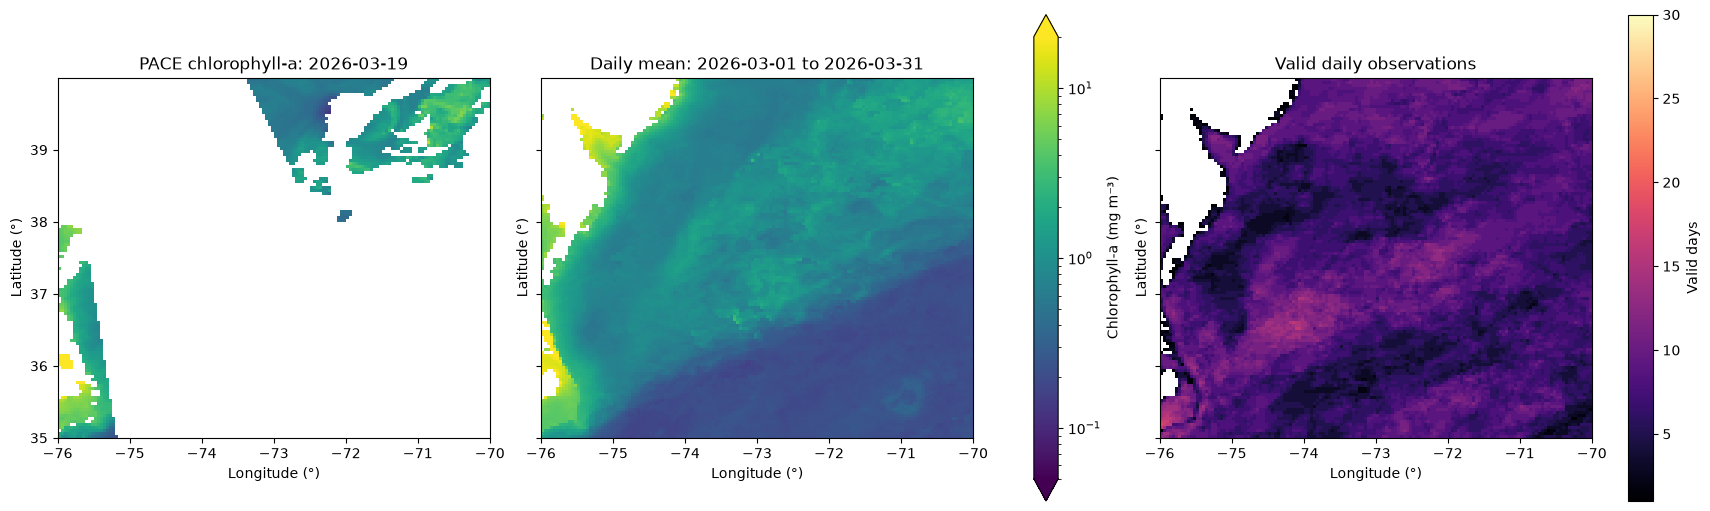

In [9]:
daily = []
for date, granule in sorted(granules.items()):
    name = granule["umm"]["GranuleUR"]
    with xr.open_dataset(remote_dir / name) as ds:
        chlor = ds["chlor_a"]
        valid = chlor.where((chlor >= chlor.attrs["valid_min"]) &
                            (chlor <= chlor.attrs["valid_max"]) & (chlor > 0)).load()
        daily.append(valid.expand_dims(time=[date]))
daily_chlor = xr.concat(daily, dim="time", join="exact")
monthly_chlor = daily_chlor.mean(dim="time", skipna=True)
valid_day_count = daily_chlor.count(dim="time")
if pd.Timestamp(example_date) not in granules:
    raise ValueError(f"No file for {example_date}; choose an available day.")
print(f"Valid pixels on {example_date}: {daily_chlor.sel(time=example_date).count().item()}")

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True, constrained_layout=True)
norm = LogNorm(vmin=0.05, vmax=20)
for ax, data, title in zip(axes[:2], [daily_chlor.sel(time=example_date), monthly_chlor],
                           [f"PACE chlorophyll-a: {example_date}", f"Daily mean: {start_date} to {end_date}"]):
    image = data.plot.pcolormesh(ax=ax, x="lon", y="lat", norm=norm, cmap="viridis", add_colorbar=False)
    ax.set(title=title, xlabel="Longitude (°)", ylabel="Latitude (°)")
    ax.set_aspect("equal")
fig.colorbar(image, ax=axes[:2], label="Chlorophyll-a (mg m⁻³)", extend="both")
valid_day_count.where(valid_day_count > 0).plot.pcolormesh(
    ax=axes[2], x="lon", y="lat", cmap="magma", vmin=1,
    vmax=daily_chlor.sizes["time"], cbar_kwargs={"label": "Valid days"})
axes[2].set(title="Valid daily observations", xlabel="Longitude (°)", ylabel="Latitude (°)")
axes[2].set_aspect("equal")
plt.show()

In [10]:
# Dask test
file_path = 'pace_mab_comparison/full/PACE_OCI.20260302.L3m.DAY.BGC.V3_2.4km.nc'
ds = xr.open_mfdataset(file_path)
print(f"File on disk: {Path(file_path).stat().st_size / 1e6:.1f} MB")
print(f"Dataset arrays: {ds.nbytes / 1e6:.1f} MB")

File on disk: 11.8 MB
Dataset arrays: 597.2 MB


## Results and recommendations

Two runs on November 13, 2026 used March 2026 daily PACE OCI BGC data, the MAB bounds above, and `chlor_a` and `poc`. Both searches found 30 daily files, with March 20 missing. The full-download cell reported no existing full files at the start of each run.

| Workflow | First run | Second run | Saved data |
| --- | ---: | ---: | --- |
| 4 km full download | 23.7 s | 15.1 s | 1,224.16 MB of global daily files |
| 4 km local subsetting | 0.7 s | 0.8 s | 1.69 MB of daily subsets |
| 4 km download + local subsetting | 24.5 s | 16.0 s | Both sets above |
| 4 km remote daily subsets | 239.0 s | 238.2 s | 1.69 MB of daily subsets |
| 0.1° remote multi-file subset | 107.4 s | 110.6 s | 0.18 MB combined daily time series |

Times are rounded; combined times use the unrounded measurements. In these runs, downloading the full files and subsetting locally was roughly 10–15 times faster than the 4 km remote daily workflow, at the cost of retaining about 1.2 GB of global files. The remote timings were similar across the two runs; the fresh-download timing varied more.

**Recommendation:** For this month and region, start with the 4 km full-download plus local-subsetting workflow when disk space is available. It retains all source variables and makes subsequent regional analyses convenient. The remote approach may be worth considering when local storage is constrained, but took longer here. Choose the variables to retain in the subsets in the settings cell.

These are two observations, not a controlled benchmark. The full-file download uses parallel requests; the 4 km remote test reads one file at a time; the 0.1° test uses a different resolution and output layout. Network conditions, caching, prior reads, and compression can affect results. **Saved file size is not network bytes transferred**, and matching subset sizes do not prove that values are identical. The 0.1° result trades spatial detail for a smaller saved subset.

The plotted monthly map is an equal-weight mean of valid daily pixel values, with the number of contributing days shown separately. NASA's OCI example opens a pre-generated monthly composite instead; it is not necessarily equivalent to this daily mean. Consider the pre-generated monthly product if only a monthly map is needed, and compare its methodology before treating the two as interchangeable.